<a href="https://colab.research.google.com/github/juheesun/-/blob/main/KShip_B_colab_runner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# B · 마진 모델 + 시나리오 엔진 + SHAP — Colab 실행 노트북

`modeling_B.zip`의 `.py` 코드를 Colab에서 그대로 돌리는 노트북입니다. 코드는 한 벌이라 VSC에서 돌려도 결과가 같습니다.

**올릴 파일 (한 번에 선택)**
| 파일 | 출처 |
|---|---|
| `dataset.json`, `fx_history.json`, `market_monthly.json` | 데이터셋 |
| `modeling_B.zip` | B 코드 |
| `features.py`, `win_model.py` | **A 팀원** 코드 |
| `win_logit.pkl` | A 팀원 모델 (`modeling/models/`) |
| `win_oof.csv` (선택) | A 팀원 LOAO 예측 (`bid_id, p_oof`) — 있으면 선택 편향 가중치에 사용 |

> **A 파일이 아직 없으면** 1단계 마지막 셀이 테스트용 대역을 자동으로 만들어 줍니다 (수치는 진짜 아님).
>
> A 코드의 컬럼 이름이 다르면 2단계 끝의 계약 점검이 알려줍니다. 알려준 이름을 `modeling/b_common.py`의 `COL`에서 고치세요 (4단계 셀 참고).

## 0. 설치

In [15]:
import sys, subprocess, os, shutil, zipfile, glob
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], capture_output=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], capture_output=True)   # 그래프 한글
    shutil.rmtree(os.path.expanduser("~/.cache/matplotlib"), ignore_errors=True)               # 폰트 캐시 갱신
print("준비 완료 (Colab)" if IN_COLAB else "준비 완료 (로컬)")

준비 완료 (Colab)


## 1. 파일 올리기 · 폴더 구성

In [16]:
ROOT = "/content/work" if IN_COLAB else os.path.abspath(".")
MOD = os.path.join(ROOT, "modeling")
for d in ("", "modeling", "modeling/models", "modeling/processed", "modeling/figures"):
    os.makedirs(os.path.join(ROOT, d), exist_ok=True)

need = ["dataset.json", "fx_history.json", "market_monthly.json"]
if IN_COLAB and not all(os.path.exists(os.path.join(ROOT, f)) for f in need):
    from google.colab import files
    print("위 표의 파일을 한 번에 선택해서 올리세요.")
    up = files.upload()
    for name in up:                                    # 올린 파일을 제자리로
        src = os.path.join("/content", name)
        if name.endswith(".json"):            dst = os.path.join(ROOT, name)
        elif name.endswith(".zip"):           zipfile.ZipFile(src).extractall(os.path.join(ROOT, "_b_zip")); continue
        elif name in ("features.py", "win_model.py"): dst = os.path.join(MOD, name)
        elif name.endswith(".pkl"):           dst = os.path.join(MOD, "models", name)
        elif name == "win_oof.csv":           dst = os.path.join(MOD, "processed", name)
        else:                                  dst = os.path.join(ROOT, name)
        shutil.move(src, dst)
    for f in glob.glob(os.path.join(ROOT, "_b_zip", "**", "*.py"), recursive=True) + glob.glob(os.path.join(ROOT, "_b_zip", "**", "*.md"), recursive=True):
        shutil.copy(f, MOD)

os.chdir(ROOT)
print("작업 폴더:", ROOT)
for p in sorted(glob.glob("*.json") + glob.glob("modeling/*.py") + glob.glob("modeling/models/*") + glob.glob("modeling/processed/*")):
    print("  ", p)
required = [f"modeling/{f}" for f in ("b_common.py", "margin_model.py", "scenario_engine.py", "05_train_margin.py", "06_run_scenarios.py", "07_run_shap.py", "features.py", "win_model.py", "models/win_logit.pkl")]
missing = [f for f in required if not os.path.exists(f)]
print("\n빠진 파일:", missing if missing else "없음 ✓")

작업 폴더: /content/work
   dataset.json
   fx_history.json
   market_monthly.json
   modeling/05_train_margin.py
   modeling/06_run_scenarios.py
   modeling/07_run_shap.py
   modeling/b_common.py
   modeling/explain.py
   modeling/features.py
   modeling/margin_model.py
   modeling/models/margin_model.pkl
   modeling/models/win_logit.pkl
   modeling/plots.py
   modeling/processed/margin_report.txt
   modeling/processed/scenario_report.txt
   modeling/processed/shap_report.txt
   modeling/scenario_engine.py
   modeling/win_model.py

빠진 파일: 없음 ✓


In [17]:
# A 팀원 파일이 하나라도 없으면, 연결 테스트용 '대역'을 만들어 B 코드를 먼저 돌려봅니다.
# ※ 대역 모델은 A의 문서(ship 7피처 로지스틱)를 흉내낸 것이라 낙찰확률 수치는 진짜가 아닙니다. 발표에 쓰지 마세요.
a_files = ["modeling/features.py", "modeling/win_model.py", "modeling/models/win_logit.pkl"]
USING_STUB = (not all(os.path.exists(f) for f in a_files)) or ("TEST STUB" in open("modeling/features.py", encoding="utf-8").read())
if USING_STUB:
    FEATURES_STUB = r'''# TEST STUB: A 문서의 사용법만 흉내낸 임시 모듈 (납품물 아님)
import json, numpy as np, pandas as pd
EXCLUDE_VARIANTS = ("E",)
FEATURE_SETS = {"ship": ["price_ratio","lead_months","log_size","num_ships","spec_scrubber","spec_lng_df","is_new_owner"]}
def _mb(a,b):
    ya,ma=map(int,a.split("-")); yb,mb=map(int,b.split("-")); return (yb-ya)*12+mb-ma
def load_table(path):
    rows=[]
    for g in json.load(open(path,encoding="utf-8")):
        for r in [g["real"]]+g.get("scenarios",[]):
            s,p,c=r["ship"],r["price"],r["cost_at_bid"]
            rows.append(dict(bid_id=r["bid_id"],variant=(r.get("scenario") or {}).get("variant","REAL"),anchor_id=r["anchor_id"],
              use_in_training=r["use_in_training"],won=int(r["outcome"]["won"]),
              price_ratio=p["price_ratio"],lead_months=_mb(s["bid_month"],s["delivery_month"]),log_size=np.log(s["size_teu"]),
              num_ships=s["num_ships"],spec_scrubber=float(s["spec_scrubber"]),spec_lng_df=float(s["spec_lng_df"]),is_new_owner=float(s["is_new_owner"]),
              quote_usd_mn=p["quote_usd_mn"],market_price_usd_mn=p["market_price_usd_mn"],bep_usd_mn=c["bep_usd_mn"]))
    return pd.DataFrame(rows)
def price_grid(row,lo=0.85,hi=1.15,n=61):
    ratios=np.linspace(lo,hi,n); g=pd.DataFrame([row.to_dict()]*n)
    g["price_ratio"]=ratios; g["quote_usd_mn"]=ratios*row["market_price_usd_mn"]; return g
'''
    WINMODEL_STUB = r'''# TEST STUB
import pickle, numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
class WinModel:
    def __init__(self,feats): self.feature_names=feats; self.pipe=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,max_iter=2000))
    def fit(self,df): self.pipe.fit(df[self.feature_names],df["won"]); return self
    def predict_proba(self,df): return self.pipe.predict_proba(df[self.feature_names])[:,1]
    def save(self,p): pickle.dump(self,open(p,"wb"))
    @classmethod
    def load(cls,p): return pickle.load(open(p,"rb"))
'''
    open("modeling/features.py", "w", encoding="utf-8").write(FEATURES_STUB)
    open("modeling/win_model.py", "w", encoding="utf-8").write(WINMODEL_STUB)
    sys.path.insert(0, os.path.join(ROOT, "modeling"))
    import features as _f, win_model as _w
    _t = _f.load_table(os.path.join(ROOT, "dataset.json"))
    _tr = _t[_t.use_in_training & ~_t.variant.isin(list(_f.EXCLUDE_VARIANTS))]
    _w.WinModel(_f.FEATURE_SETS["ship"]).fit(_tr).save(os.path.join(MOD, "models", "win_logit.pkl"))
    print("=" * 70)
    print("⚠ A 파일이 없어 [테스트용 대역]을 만들었습니다.")
    print("  → 코드가 끝까지 도는지 확인하는 용도입니다. 낙찰확률·기대가치 수치는 진짜가 아닙니다.")
    print("  → A 파일을 받으면 1단계에서 올리고 노트북을 처음부터 다시 실행하세요 (진짜 파일이 올라오면 대역은 자동으로 대체됩니다).")
    print("=" * 70)
else:
    print("A 팀원 파일 확인 ✓ (실제 모델로 실행)")

⚠ A 파일이 없어 [테스트용 대역]을 만들었습니다.
  → 코드가 끝까지 도는지 확인하는 용도입니다. 낙찰확률·기대가치 수치는 진짜가 아닙니다.
  → A 파일을 받으면 1단계에서 올리고 노트북을 처음부터 다시 실행하세요 (진짜 파일이 올라오면 대역은 자동으로 대체됩니다).


## 2. A 코드와 연결 점검

A의 `features.py` / `win_model.py` / `win_logit.pkl`이 B가 기대하는 모양인지 확인합니다. **여기서 막히면 아래 4단계의 `COL` 수정을 먼저 보세요.**

In [18]:
sys.path.insert(0, os.path.join(ROOT, "modeling"))
import importlib, b_common
importlib.reload(b_common)
features, model, table = b_common.load_win_assets()
b_common.check_contract(features, model, table)
print("A 모델 피처:", b_common.win_feature_names(model, features))
table.head(3)

[계약 점검 통과] 피처 ['price_ratio', 'lead_months', 'log_size', 'num_ships', 'spec_scrubber', 'spec_lng_df', 'is_new_owner']
A 모델 피처: ['price_ratio', 'lead_months', 'log_size', 'num_ships', 'spec_scrubber', 'spec_lng_df', 'is_new_owner']


,bid_id,variant,anchor_id,use_in_training,won,price_ratio,lead_months,log_size,num_ships,spec_scrubber,spec_lng_df,is_new_owner,quote_usd_mn,market_price_usd_mn,bep_usd_mn
0,REAL-01,REAL,REAL-01,True,1,1.0015,33,9.648595,2,0.0,0.0,0.0,194.79,194.5,175.05
1,REAL-01-D,D,REAL-01,True,1,0.9013,33,9.648595,2,0.0,0.0,0.0,175.31,194.5,175.05
2,REAL-01-E,E,REAL-01,True,0,0.9514,33,9.648595,2,0.0,0.0,0.0,185.05,194.5,175.05


## 3. 05 · 마진 모델 + 선택 편향 점검

In [19]:
!python modeling/05_train_margin.py

[계약 점검 통과] 피처 ['price_ratio', 'lead_months', 'log_size', 'num_ships', 'spec_scrubber', 'spec_lng_df', 'is_new_owner']
1. 마진 구조식 검증: 실제 마진 = 1 − 추정원가×(1+원가초과) ÷ (견적가×인도환율÷100)
낙찰 34건, 공식과 데이터의 최대 차이 = 0.0001  → 마진은 '환율 변화'와 '원가 초과' 두 값으로 완전히 결정됨
입찰 시점에 모르는 값은 이 둘뿐이라, 회귀로 배우지 않고 분포에서 뽑아 기대 마진·손실 확률을 계산한다.

2. 학습 행 중 낙찰 건의 구성
         건수  평균_마진  평균_원가초과  평균_환율변화
variant                             
D         8 -0.136     0.04    -0.07
J         8  0.017     0.00    -0.07
K         8  0.013     0.08     0.00
REAL      8  0.086     0.00     0.00
→ 낙찰 32건 중 환율·원가 충격 변형(D·J·K)이 24건. 학습 낙찰 건은 '충격이 많이 섞인 표본'이다.

4. 낙찰 건 '충격(실제 마진 − 규칙 마진)' 평균 추정 · 낙찰확률 출처: 학습 데이터 위 예측 (win_oof.csv 가 없어 in-sample 사용 → 약간 낙관적)
낙찰 건만의 단순 평균 (선택 편향 있음)          -0.0655
낙찰 건 IPW 가중 평균                   -0.0604
구조식 + 환율·원가 시뮬레이션 (전체 학습 행 평균)   -0.0317
→ 낙찰 건 평균은 충격 변형이 많아 크게 음수로 나온다. IPW 로 보정해도 큰 변화가 없으면(위 첫 두 줄) 편향의 원인이
   '누가 낙찰됐나'보다 '낙찰 건에 충격 변형이 많이 섞인 구성'이라는 뜻이다. 그래서 낙찰 건 회귀 대신 시뮬레이션을 쓴다.

5. 참고 · LOAO (anchor 하나

## 4. 06 · 기대가치 곡선 · 반사실 시나리오 · 역방향 탐색

In [20]:
# 분석할 입찰을 바꾸려면 REAL-01 ~ REAL-10 중 하나로
FOCUS = "REAL-10"
!python modeling/06_run_scenarios.py {FOCUS}

[계약 점검 통과] 피처 ['price_ratio', 'lead_months', 'log_size', 'num_ships', 'spec_scrubber', 'spec_lng_df', 'is_new_owner']
1. 실제 건별 권장가 (정책: 기대가치 ≥ 최고의 85% 구간의 하한)
            제안가  낙찰확률    손익분기     봉우리         권장 구간     권장가 환율손실확률(제안가)
입찰                                                                     
REAL-01  $194.8   63%  -10.0%  $193.5  $187.7~199.4  $187.7         24%
REAL-02  $198.4   71%  -10.0%  $198.4  $192.5~204.8  $192.5         24%
REAL-03  $149.1   53%  -10.0%  $167.1  $164.9~170.7  $164.9         81%
REAL-04  $188.1   56%  -10.0%  $185.8  $180.7~191.5  $180.7         28%
REAL-05  $183.1   69%  -10.0%  $182.8  $177.3~188.3  $177.3         23%
REAL-06  $183.4   76%  -10.0%  $185.1  $179.1~190.6  $179.1         26%
REAL-07   $42.9   97%  -10.0%   $45.0    $42.9~46.6   $42.9         12%
REAL-08   $55.3  100%  -10.0%   $63.8    $60.7~65.1   $60.7         31%
REAL-09  $198.8   65%  -10.0%  $197.9  $192.0~203.9  $192.0         26%
REAL-10  $190.6   58%  -10.0%  $185.3  $178.2~191

REAL-10_ev_base.png


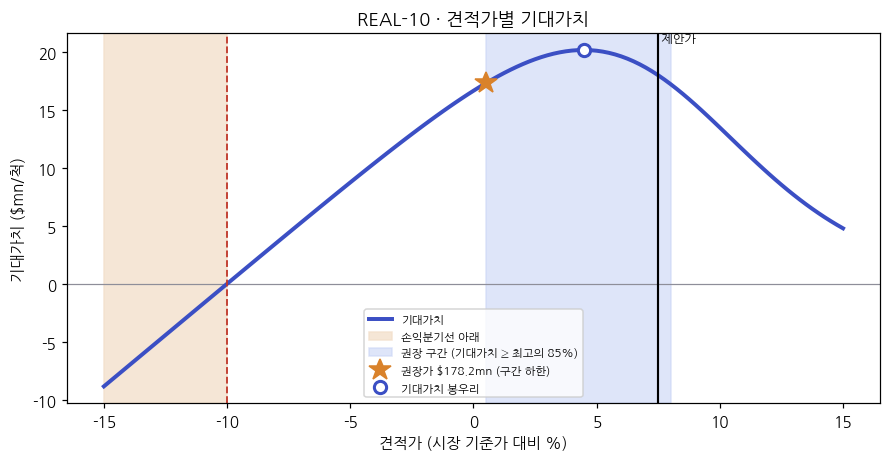

REAL-10_fx_risk.png


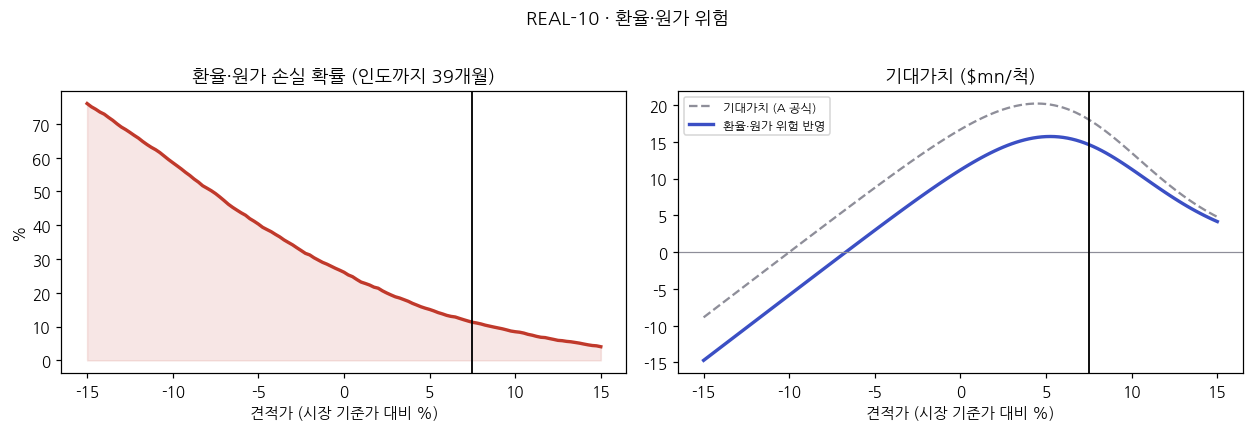

REAL-10_ev_scenario.png


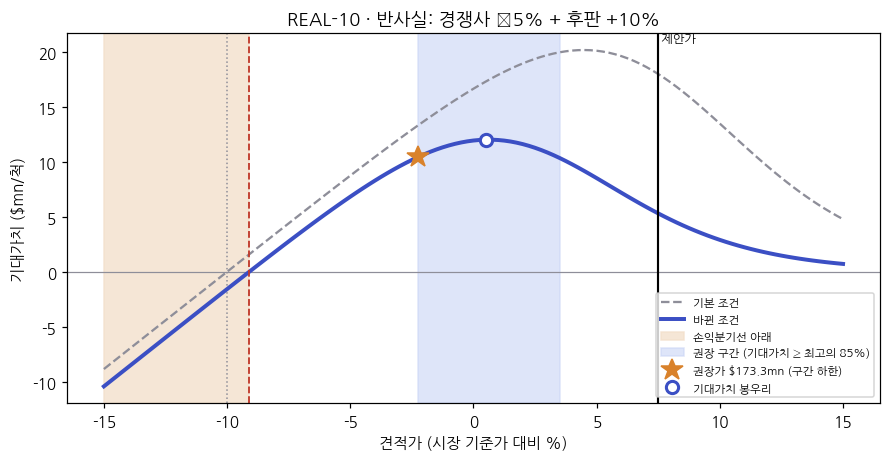

In [21]:
from IPython.display import Image, display
for f in (f"{FOCUS}_ev_base.png", f"{FOCUS}_fx_risk.png", f"{FOCUS}_ev_scenario.png"):
    print(f); display(Image(os.path.join("modeling/figures", f)))

## 5. 시나리오 직접 눌러보기 (선택형)

슬라이더로 조건을 바꾸면 기본(점선)과 바뀐 조건(파란 선)이 바로 비교됩니다. 낙찰확률·기대가치 숫자 카드도 같이 나옵니다.

,기본,바뀐 조건
낙찰확률(제안가),58.0%,18.1%
기대가치 $mn/척,18.01,5.31
환율·원가 손실확률,11.3%,12.9%
권장가(구간 하한),$178.2,$173.3


⚠ 한글 폰트를 못 찾았습니다. 그래프 글자가 깨질 수 있어요.


/content/work/modeling/plots.py:33: UserWarning: Glyph 44204 (\N{HANGUL SYLLABLE GYEON}) missing from font(s) DejaVu Sans.
  ax.set_title(title); ax.legend(fontsize=7.5, loc="best"); plt.tight_layout()
/content/work/modeling/plots.py:33: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  ax.set_title(title); ax.legend(fontsize=7.5, loc="best"); plt.tight_layout()
/content/work/modeling/plots.py:33: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  ax.set_title(title); ax.legend(fontsize=7.5, loc="best"); plt.tight_layout()
/content/work/modeling/plots.py:33: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  ax.set_title(title); ax.legend(fontsize=7.5, loc="best"); plt.tight_layout()
/content/work/modeling/plots.py:33: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  ax.set_title(title); ax.legend(fontsize=7.5, loc="best"); plt.tight_layout(

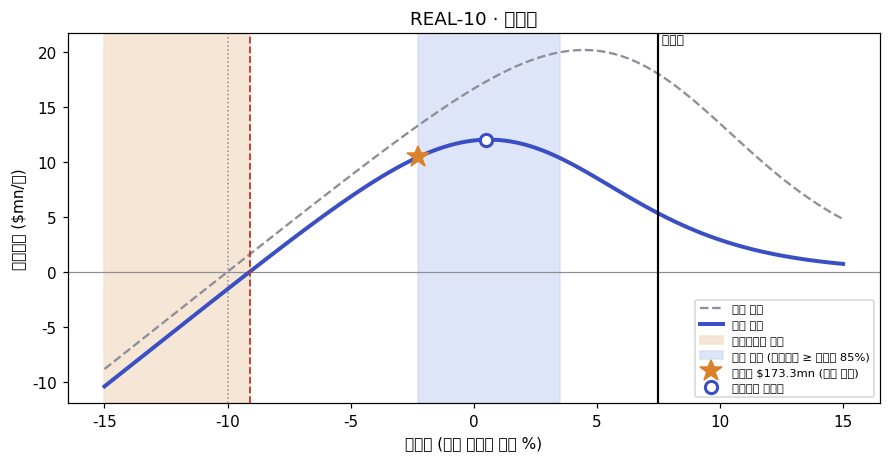

In [22]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from b_common import load_raw, MODELS, pct
from margin_model import MarginModel
from scenario_engine import ScenarioEngine, Scenario
from plots import plot_ev

raw = load_raw(); mm = MarginModel.load(MODELS / "margin_model.pkl")
eng = ScenarioEngine(model, features.price_grid, table, raw, mm)

def show(bid, **cond):
    sc = Scenario("선택한 조건", **cond)
    c = eng.compare(bid, sc); b, s = c["base"].summary, c["scen"].summary
    card = pd.DataFrame({"기본": [f"{b['p_now']:.1%}", f"{b['ev_now']:.2f}", f"{b['loss_prob_now']:.1%}", f"${b['recommended']:.1f}"],
                         "바뀐 조건": [f"{s['p_now']:.1%}", f"{s['ev_now']:.2f}", f"{s['loss_prob_now']:.1%}", (f"${s['recommended']:.1f}" if s["recommended"] else "없음")]},
                        index=["낙찰확률(제안가)", "기대가치 $mn/척", "환율·원가 손실확률", "권장가(구간 하한)"])
    display(card)
    plot_ev(c["scen"], c["base"], title=f"{bid} · 반사실"); plt.show()

show(FOCUS, comp_pct=-0.05, steel_pct=0.10)     # 예: 경쟁사 −5% + 후판가 +10%

In [23]:
try:
    import ipywidgets as w
    from IPython.display import clear_output
    sty = {"description_width": "110px"}
    bid_w = w.Dropdown(options=list(raw.index[raw.variant == "REAL"]), value=FOCUS, description="입찰")
    comp = w.FloatSlider(value=0, min=-15, max=15, step=1, description="경쟁사 견적 %", style=sty)
    steel = w.FloatSlider(value=0, min=-20, max=30, step=5, description="후판가 %", style=sty)
    fxw = w.FloatSlider(value=0, min=-15, max=10, step=1, description="환율 %", style=sty)
    dly = w.IntSlider(value=0, min=0, max=12, step=1, description="납기 지연(월)", style=sty)
    out = w.Output()
    def upd(_=None):
        with out:
            clear_output(wait=True)
            show(bid_w.value, comp_pct=comp.value/100, steel_pct=steel.value/100, fx_pct=fxw.value/100, delay_months=dly.value)
    for c in (bid_w, comp, steel, fxw, dly): c.observe(upd, names="value")
    display(w.VBox([bid_w, comp, steel, fxw, dly, out])); upd()
except ImportError:
    print("ipywidgets 가 없어 건너뜁니다.")

## 6. 07 · SHAP 요인 분해

In [24]:
!python modeling/07_run_shap.py {FOCUS}

[계약 점검 통과] 피처 ['price_ratio', 'lead_months', 'log_size', 'num_ships', 'spec_scrubber', 'spec_lng_df', 'is_new_owner']
낙찰확률 모델 설명 (모델 불가지 SHAP, 확률 공간). * = anchor 이름표 가능성이 있는 이진 피처 → 해석 제외
※ 확률(0~100%)은 S자 곡선이라, 바뀌지 않은 피처의 기여도 시나리오에서 함께 움직일 수 있음 (상호작용). 가장 큰 막대 중심으로 읽기.
피처: ['price_ratio', 'lead_months', 'log_size', 'num_ships', 'spec_scrubber', 'spec_lng_df', 'is_new_owner'] · 학습 72건 · 독립 anchor 8개 → 값은 방향과 상대 크기로만 읽기

[1] 글로벌 중요도 (평균 |SHAP|, %p)
견적가 비율        26.64
척수            13.45
납기까지 개월       13.00
신규 선주*        11.87
LNG 이중연료*      5.31
스크러버*          4.54
선박 크기(log)     0.41

[2] REAL-10 낙찰확률 58.0% = 평균 44.5% + 요인 합 +13.6%p
견적가 비율       -27.10
납기까지 개월       -0.39
선박 크기(log)     0.82
스크러버*          2.97
신규 선주*         9.70
척수            13.26
LNG 이중연료*     14.33

[3] 시나리오: 경쟁사 −5% + 후판 +10%
기대가치 18.01 → 5.31 $mn (변화 -12.70 = 낙찰확률 효과 -12.41 + 건당 이익 효과 -0.29)
낙찰확률 변화의 피처별 기여(%p): 견적가 비율 -21.3, LNG 이중연료* -5.9, 척수 -5.3, 신규 선주* -4.8, 납기까지 개월 -1.6, 스크러버* -0.9, 선박 크기(log) -0.2
/conten

shap_global.png


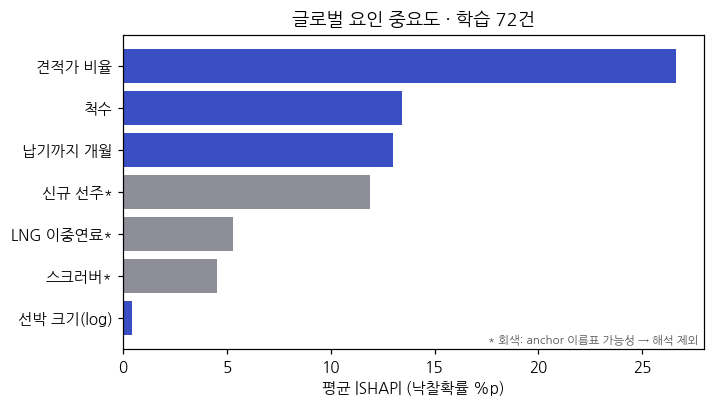

shap_local_REAL-10.png


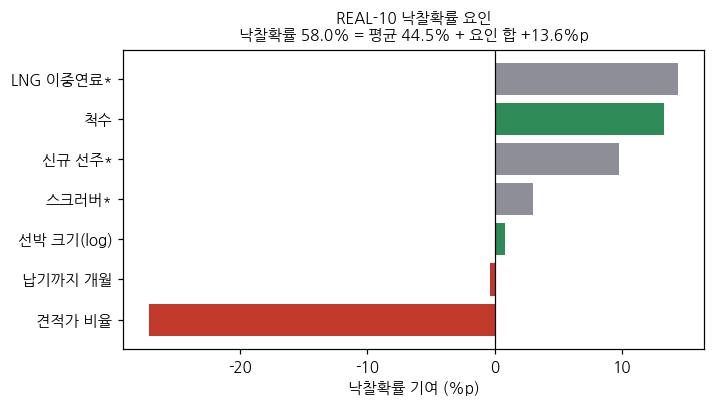

shap_margin_REAL-10.png


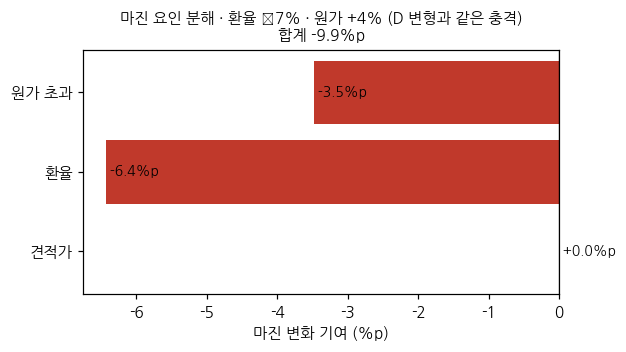

shap_scenario_경쟁사_REAL-10.png


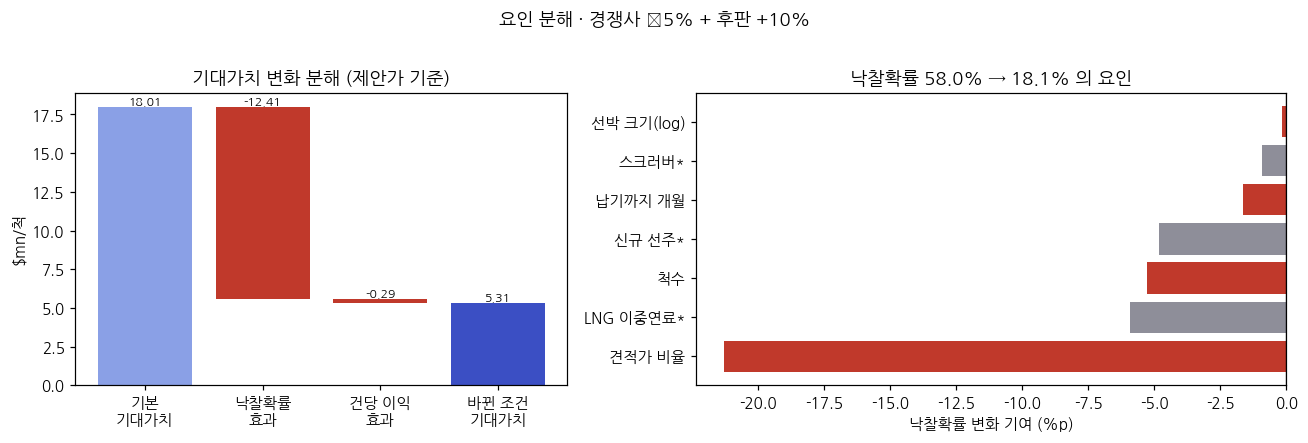

shap_scenario_납기__REAL-10.png


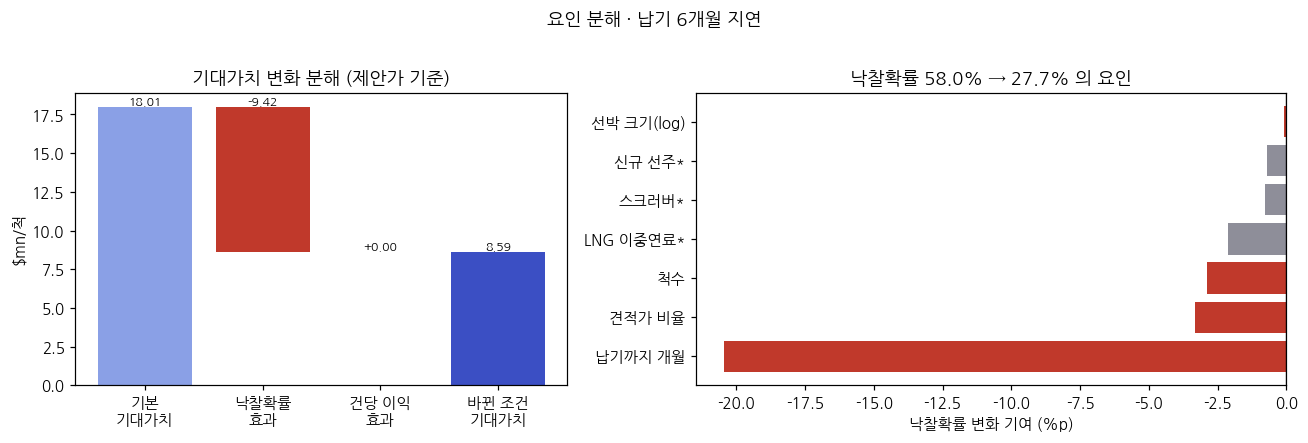

In [25]:
for f in sorted(glob.glob(f"modeling/figures/shap_*")):
    print(os.path.basename(f)); display(Image(f))

## 7. 결과 내려받기

In [26]:
shutil.make_archive("B_results", "zip", "modeling", "processed")
shutil.make_archive("B_figures", "zip", "modeling", "figures")
shutil.copy("modeling/models/margin_model.pkl", "margin_model.pkl")
print("만들어진 파일: B_results.zip(보고서), B_figures.zip(그래프), margin_model.pkl")
if IN_COLAB:
    from google.colab import files
    for f in ("B_results.zip", "B_figures.zip", "margin_model.pkl"): files.download(f)

만들어진 파일: B_results.zip(보고서), B_figures.zip(그래프), margin_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 문제가 생기면
- **`[계약 위반] … 컬럼이 없습니다`** → A 코드의 컬럼 이름이 다릅니다. 메시지에 나온 현재 컬럼을 보고 `modeling/b_common.py`의 `COL` 딕셔너리를 고치세요. (Colab 왼쪽 파일 탭에서 열어 수정 후 2단계부터 다시 실행)
- **`win_logit.pkl 이 없습니다`** → A의 `03_train_models.py` 결과 파일을 올리세요.
- **그래프 한글이 깨짐** → 0단계를 다시 실행하고 런타임을 재시작하세요.
- 수치를 발표에 쓸 땐 A의 실제 모델로 돌린 결과인지 확인하세요 (연결 점검이 통과해야 합니다).